<a id="top"></a>

# Network Partitioning Notebook

<div style="padding:18px 22px; border-left:6px solid #2563eb; background:#eff6ff; border-radius:10px; margin:14px 0 20px 0;">
  <h3 style="margin:0 0 8px 0; color:#0f172a;">Notebook Roadmap</h3>
  <p style="margin:0; color:#334155; font-size:15px;">
    This notebook demonstrates graph partitioning on a small hand-built graph with two dense communities connected by one bridge edge. The small graph makes every cut, swap, move, and cluster easy to inspect visually.
  </p>
</div>

## Clickable Algorithm Index

| Section | Topic | What you will see |
|---:|---|---|
| 0 | [Graph setup](#graph-setup) | Build the manual graph, list node connections, and list edges |
| 1 | [Karger's randomized min-cut](#karger) | Random contraction idea and true min-cut visualization |
| 2 | [Kernighan-Lin (KL)](#kl) | Manual KL gain tables, swaps, final partition, and NetworkX comparison |
| 3 | [Fiduccia-Mattheyses (FM)](#fm) | Manual FM gain table, single-node moves, and final partition |
| 4 | [Multilevel / METIS](#metis) | PyMetis-based 2-way multilevel partitioning |
| 5 | [Spectral partitioning](#spectral) | Matrix construction, Fiedler vector, and sign-based split |
| 6 | [MCL library version](#mcl-library) | Markov Clustering using the external library |
| 7 | [Manual MCL](#manual-mcl) | Scratch expansion, inflation, pruning, and cluster extraction |

> **Navigation tip:** click any topic name above to jump directly to that section. Each major section also has a **Back to top** link.


<a id="graph-setup"></a>

### Cell: Build and visualize the graph

<div style="padding:14px 18px; background:#f8fafc; border:1px solid #dbe3ef; border-radius:10px;">
  <b>Goal:</b> create a small graph with two dense node groups and one bridge edge between them.
</div>

The graph is intentionally simple:

- Left community: nodes `0, 1, 2, 3`
- Right community: nodes `4, 5, 6, 7`
- Bridge edge: `(3, 4)`

This structure makes the correct partition visually obvious and useful for learning each algorithm step by step.

[Back to top](#top)


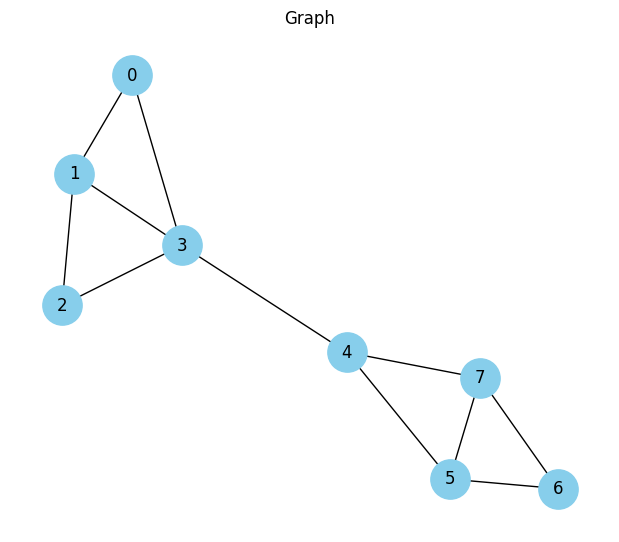

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
G=nx.Graph()
G.add_edges_from([

                  (0,1),(1,2),(2,3),(0,3),(1,3)
])

G.add_edges_from([
    (4,5),(5,6),(6,7),(4,7),(5,7)
])

G.add_edge(3,4)
pos=nx.spring_layout(G,seed=42)
plt.figure(figsize=(6,5))
nx.draw(G,pos,with_labels=True,node_color="skyblue",node_size=800)
plt.title("Graph")
plt.show()

### Cell: Print node connections

This cell prints the adjacency list: for every node, it shows which nodes are directly connected to it. This helps verify the graph before applying partitioning algorithms.


In [4]:
# Show who is connected to whom

print("Node connections:\n")

for node in sorted(G.nodes()):
    neighbors = sorted(list(G.neighbors(node)))
    print(f"{node} is connected to {neighbors}")

Node connections:

0 is connected to [1, 3]
1 is connected to [0, 2, 3]
2 is connected to [1, 3]
3 is connected to [0, 1, 2, 4]
4 is connected to [3, 5, 7]
5 is connected to [4, 6, 7]
6 is connected to [5, 7]
7 is connected to [4, 5, 6]


### Cell: Print edge list

This cell prints all edges in the graph. The edge list is useful for manually checking crossing edges and cut size.


In [5]:
print("Edges in the graph:")
print(sorted(G.edges()))

Edges in the graph:
[(0, 1), (0, 3), (1, 2), (1, 3), (2, 3), (3, 4), (4, 5), (4, 7), (5, 6), (5, 7), (6, 7)]


<a id="karger"></a>

# 1. Karger's Randomized Min-Cut Algorithm

<div style="padding:16px 20px; border-left:6px solid #dc2626; background:#fef2f2; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#7f1d1d;">Core idea</h3>
  <p style="margin:0; color:#374151;">Randomly contract edges until two supernodes remain. The remaining edges between them form a candidate cut.</p>
</div>

| Item | Description |
|---|---|
| Objective | Find a global minimum edge cut |
| Why repeated runs matter | Random choices can produce different cuts |
| Expected cut in this graph | The bridge edge `(3, 4)` |
| Visualization | The final min-cut edge is highlighted in red |

[Back to top](#top)


## Karger's Algorithm: Pseudocode and Example

**Input:** Graph \(G=(V,E)\)  
**Output:** A cut of the graph

```text
KARGER_MIN_CUT(G):

1. Make a copy of graph G.
2. While the number of vertices is greater than 2:
      a. Randomly choose an edge (u, v).
      b. Contract the edge by merging u and v into one super-node.
      c. Remove self-loops because they stay inside one super-node.
3. Count the remaining edges between the two final super-nodes.
4. Return the cut value.
5. Repeat several times and keep the smallest cut.
```

A **self-loop** is removed because it connects a super-node to itself and cannot be a crossing edge.


### Cell: Run Karger's randomized min-cut

This cell defines a simple Karger min-cut function. It runs the randomized contraction process 50 times and prints the smallest cut found. Multiple runs are needed because a random run may contract the bridge edge too early.


In [5]:
import random, copy
def karger_min_cut(G):
  G=copy.deepcopy(G)
  while len(G.nodes)>2:
    u,v=random.choice(list(G.edges))
    G=nx.contracted_nodes(G,u,v,self_loops=False)
  return G.number_of_edges()


cuts=[karger_min_cut(G) for _ in range(50)]
print("karger Min Cut :", min(cuts))


karger Min Cut : 1


### Cell: Visualize the min-cut

This cell uses `nx.minimum_edge_cut` to identify the true minimum cut edge, removes it temporarily to find the two separated components, and draws the cut edge as a red dashed line.


Cut edge(s): [(3, 4)]
Partition 1: [0, 1, 2, 3]
Partition 2: [4, 5, 6, 7]
Cut size: 1


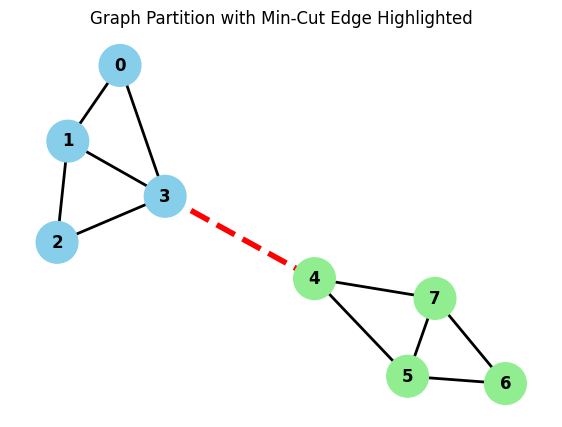

In [6]:

# Find the minimum cut edge(s)
cut_edges = list(nx.minimum_edge_cut(G))

print("Cut edge(s):", cut_edges)

# Remove cut edge(s) to see the separated components
H = G.copy()
H.remove_edges_from(cut_edges)

components = list(nx.connected_components(H))
components = sorted(components, key=lambda x: min(x))

print("Partition 1:", sorted(components[0]))
print("Partition 2:", sorted(components[1]))
print("Cut size:", len(cut_edges))

# Color nodes based on partition
node_colors = []
for node in G.nodes():
    if node in components[0]:
        node_colors.append("skyblue")
    else:
        node_colors.append("lightgreen")

plt.figure(figsize=(7,5))

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=900)

# Draw normal edges
normal_edges = [e for e in G.edges() if e not in cut_edges and (e[1], e[0]) not in cut_edges]
nx.draw_networkx_edges(G, pos, edgelist=normal_edges, width=2)

# Draw cut edge(s)
nx.draw_networkx_edges(
    G, pos,
    edgelist=cut_edges,
    edge_color="red",
    width=4,
    style="dashed"
)

# Draw labels
nx.draw_networkx_labels(G, pos, font_size=12, font_weight="bold")

plt.title("Graph Partition with Min-Cut Edge Highlighted")
plt.axis("off")
plt.show()

<a id="kl"></a>

# 2. Kernighan-Lin (KL) Algorithm

<div style="padding:16px 20px; border-left:6px solid #2563eb; background:#eff6ff; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#1e3a8a;">Core idea</h3>
  <p style="margin:0; color:#334155;">Start with a balanced but bad partition, then swap pairs of nodes to reduce crossing edges.</p>
</div>

| Version in this notebook | Purpose |
|---|---|
| Manual KL | Shows external cost, internal cost, pair gain, locked swaps, and cumulative gain |
| NetworkX KL | Uses `nx.algorithms.community.kernighan_lin_bisection` for comparison |

The initial partition is deliberately mixed so the improvement process is visible.

[Back to top](#top)


## KL Algorithm: Core Idea

Initial bad partition:

\[
A = \{0,1,2,4\},  B = \{3,5,6,7\}
\]

This is balanced because both partitions contain four nodes, but it has many crossing edges.

For each node:

\[
Gain(v) = External(v) - Internal(v)
\]

where:

- **External** = edges from the node to the other partition
- **Internal** = edges from the node to the same partition

For swapping \(a \in A\) and \(b \in B\):

\[
PairGain(a,b)=Gain(a)+Gain(b)-2w(a,b)
\]

where \(w(a,b)=1\) if there is an edge between \(a\) and \(b\), otherwise 0.

In this example, KL should identify that swapping node 4 and node 3 is the best first swap.


## Manual KL Implementation

The following cells implement KL manually without using `nx.algorithms.community.kernighan_lin_bisection`. The output is designed to be clean: gain tables, pair-gain table, applied swaps, final crossing edges, and final graph visualization.


### KL Cell: Helper functions

This cell defines helper functions for the manual KL algorithm:

- `kl_crossing_edges`: finds edges crossing between partitions A and B.
- `kl_cut_size`: counts crossing edges.
- `kl_gain_table`: creates a clean table with Node, Partition, Connections, External, Internal, and Gain.


In [7]:
import pandas as pd

def kl_crossing_edges(G, A, B):
    crossing = []
    for u, v in G.edges():
        if (u in A and v in B) or (u in B and v in A):
            crossing.append((u, v))
    return crossing


def kl_cut_size(G, A, B):
    return len(kl_crossing_edges(G, A, B))


def kl_gain_table(G, A, B):
    rows = []

    for node in sorted(G.nodes()):
        connections = sorted(list(G.neighbors(node)))

        if node in A:
            partition = "A"
            same_partition = A
            other_partition = B
        else:
            partition = "B"
            same_partition = B
            other_partition = A

        external = 0
        internal = 0

        for neighbor in connections:
            if neighbor in same_partition:
                internal += 1
            elif neighbor in other_partition:
                external += 1

        gain = external - internal

        rows.append({
            "Node": node,
            "Partition": partition,
            "Connections": connections,
            "External": external,
            "Internal": internal,
            "Gain": gain
        })

    return pd.DataFrame(rows)

### KL Cell: Initial partition and gain table

This cell sets the initial balanced partition and displays the KL gain table. The initial partition is balanced but poor because it has many crossing edges.


In [8]:
A = {0, 1, 2, 4}
B = {3, 5, 6, 7}

print("Initial KL Partition")
print("A =", sorted(A))
print("B =", sorted(B))

print("\nInitial crossing edges:")
print(kl_crossing_edges(G, A, B))

print("\nInitial cut size:", kl_cut_size(G, A, B))

print("\nKL Gain Table")
display(kl_gain_table(G, A, B))

Initial KL Partition
A = [0, 1, 2, 4]
B = [3, 5, 6, 7]

Initial crossing edges:
[(0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (4, 7)]

Initial cut size: 6

KL Gain Table


,Node,Partition,Connections,External,Internal,Gain
0,0,A,"[1, 3]",1,1,0
1,1,A,"[0, 2, 3]",1,2,-1
2,2,A,"[1, 3]",1,1,0
3,3,B,"[0, 1, 2, 4]",4,0,4
4,4,A,"[3, 5, 7]",3,0,3
5,5,B,"[4, 6, 7]",1,2,-1
6,6,B,"[5, 7]",0,2,-2
7,7,B,"[4, 5, 6]",1,2,-1


Partition A: [0, 1, 2, 4]
Partition B: [3, 5, 6, 7]
Crossing edges: [(0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (4, 7)]
Cut size: 6


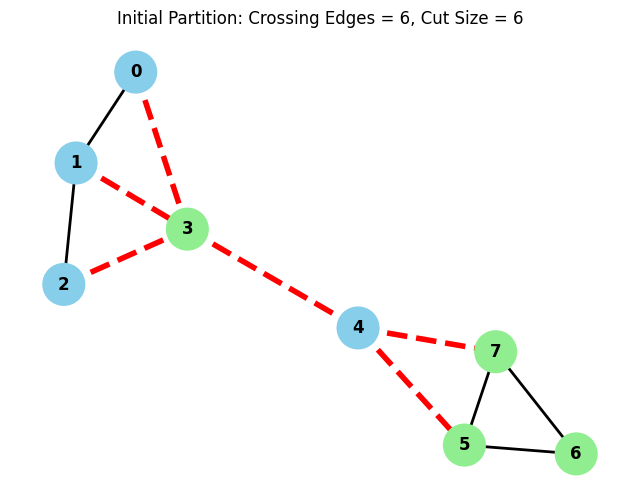

In [9]:
# Visualize initial partition crossing edges where Cut = 6

A = {0, 1, 2, 4}
B = {3, 5, 6, 7}

# Find crossing edges
crossing_edges = []

for u, v in G.edges():
    if (u in A and v in B) or (u in B and v in A):
        crossing_edges.append((u, v))

# Normal edges
cut_edge_set = {tuple(sorted(edge)) for edge in crossing_edges}

normal_edges = []

for edge in G.edges():
    if tuple(sorted(edge)) not in cut_edge_set:
        normal_edges.append(edge)

# Node colors based on partition
node_colors = []

for node in G.nodes():
    if node in A:
        node_colors.append("skyblue")
    else:
        node_colors.append("lightgreen")

print("Partition A:", sorted(A))
print("Partition B:", sorted(B))
print("Crossing edges:", crossing_edges)
print("Cut size:", len(crossing_edges))

# Draw graph
plt.figure(figsize=(8, 6))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    node_size=900
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=normal_edges,
    width=2
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=crossing_edges,
    edge_color="red",
    width=4,
    style="dashed"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=12,
    font_weight="bold"
)

plt.title("Initial Partition: Crossing Edges = 6, Cut Size = 6")
plt.axis("off")
plt.show()

### KL Cell: Pair gain table

KL swaps one node from A with one node from B. This cell calculates the pair gain for every possible swap and shows which swap gives the highest improvement.


In [10]:
def kl_pair_gain_table(G, A, B):
    gain_df = kl_gain_table(G, A, B)
    gain_dict = dict(zip(gain_df["Node"], gain_df["Gain"]))

    rows = []

    for a in sorted(A):
        for b in sorted(B):
            edge_between = 1 if G.has_edge(a, b) else 0

            pair_gain = gain_dict[a] + gain_dict[b] - 2 * edge_between
            # Pair Gain = Gain(A) + Gain(B) - 2 × Edge between them

            rows.append({
                "Node from A": a,
                "Node from B": b,
                "Gain(A)": gain_dict[a],
                "Gain(B)": gain_dict[b],
                "Edge between them": edge_between,
                "Pair Gain": pair_gain
            })

    return pd.DataFrame(rows)


kl_pair_df = kl_pair_gain_table(G, A, B)

print("KL Pair Gain Table")
display(kl_pair_df)

best_pair = kl_pair_df.loc[kl_pair_df["Pair Gain"].idxmax()]

print("Best KL Swap:")
print(f"Swap {best_pair['Node from A']} with {best_pair['Node from B']}")
print("Best pair gain:", best_pair["Pair Gain"])

KL Pair Gain Table


,Node from A,Node from B,Gain(A),Gain(B),Edge between them,Pair Gain
0,0,3,0,4,1,2
1,0,5,0,-1,0,-1
2,0,6,0,-2,0,-2
3,0,7,0,-1,0,-1
4,1,3,-1,4,1,1
5,1,5,-1,-1,0,-2
6,1,6,-1,-2,0,-3
7,1,7,-1,-1,0,-2
8,2,3,0,4,1,2
9,2,5,0,-1,0,-1


Best KL Swap:
Swap 4 with 3
Best pair gain: 5


### KL Cell: Manual KL function

This cell defines the manual KL algorithm. It creates a clean swap table containing each selected swap, pair gain, cumulative gain, and cut after the swap. Finally, it applies only the best cumulative sequence of swaps.


In [11]:
def kl_manual_clean(G, A, B):
    A = set(A)
    B = set(B)

    print("=" * 60)
    print("MANUAL KERNIGHAN-LIN ALGORITHM")
    print("=" * 60)

    print("Starting A:", sorted(A))
    print("Starting B:", sorted(B))
    print("Starting crossing edges:", kl_crossing_edges(G, A, B))
    print("Starting cut size:", kl_cut_size(G, A, B))

    A_work = set(A)
    B_work = set(B)
    locked = set()

    swap_records = []
    partition_states = []
    cumulative_gain = 0

    for step in range(min(len(A), len(B))):
        best_pair = None
        best_gain = None

        gain_df = kl_gain_table(G, A_work, B_work)
        gain_dict = dict(zip(gain_df["Node"], gain_df["Gain"]))

        for a in sorted(A_work):
            if a in locked:
                continue

            for b in sorted(B_work):
                if b in locked:
                    continue

                edge_between = 1 if G.has_edge(a, b) else 0
                pair_gain = gain_dict[a] + gain_dict[b] - 2 * edge_between

                if best_gain is None or pair_gain > best_gain:
                    best_gain = pair_gain
                    best_pair = (a, b)

        if best_pair is None:
            break

        a, b = best_pair

        A_work.remove(a)
        B_work.remove(b)
        A_work.add(b)
        B_work.add(a)

        locked.add(a)
        locked.add(b)

        cumulative_gain += best_gain

        swap_records.append({
            "Step": step + 1,
            "Swap": f"{a} <-> {b}",
            "Pair Gain": best_gain,
            "Cumulative Gain": cumulative_gain,
            "Cut After Swap": kl_cut_size(G, A_work, B_work)
        })

        partition_states.append((set(A_work), set(B_work)))

    swap_df = pd.DataFrame(swap_records)

    print("\nKL Swap Table")
    display(swap_df)

    best_index = None
    best_cumulative_gain = 0

    for i, record in enumerate(swap_records):
        if record["Cumulative Gain"] > best_cumulative_gain:
            best_cumulative_gain = record["Cumulative Gain"]
            best_index = i

    if best_index is None:
        print("\nNo positive improvement found.")
        return A, B

    final_A, final_B = partition_states[best_index]

    print("\nBest cumulative gain:", best_cumulative_gain)
    print("Apply first", best_index + 1, "swap(s).")

    print("\nFinal KL Partition")
    print("A =", sorted(final_A))
    print("B =", sorted(final_B))
    print("Final crossing edges:", kl_crossing_edges(G, final_A, final_B))
    print("Final cut size:", kl_cut_size(G, final_A, final_B))

    return final_A, final_B

### KL Cell: Run manual KL

This cell runs the manual KL algorithm on the initial partition. The expected final result is \(\{0,1,2,3\}\) and \(\{4,5,6,7\}\), with cut size 1.


In [12]:
A = {0, 1, 2, 4}
B = {3, 5, 6, 7}

final_A_kl, final_B_kl = kl_manual_clean(G, A, B)

MANUAL KERNIGHAN-LIN ALGORITHM
Starting A: [0, 1, 2, 4]
Starting B: [3, 5, 6, 7]
Starting crossing edges: [(0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (4, 7)]
Starting cut size: 6

KL Swap Table


,Step,Swap,Pair Gain,Cumulative Gain,Cut After Swap
0,1,4 <-> 3,5,5,1
1,2,0 <-> 6,-4,1,5
2,3,1 <-> 5,-2,-1,7
3,4,2 <-> 7,1,0,6



Best cumulative gain: 5
Apply first 1 swap(s).

Final KL Partition
A = [0, 1, 2, 3]
B = [4, 5, 6, 7]
Final crossing edges: [(3, 4)]
Final cut size: 1


### KL Cell: Final gain table and crossing edge

This cell displays the final gain table after KL finishes and prints the final crossing edge and cut size.


In [13]:
print("Final KL Gain Table")
display(kl_gain_table(G, final_A_kl, final_B_kl))

print("Final KL crossing edges:", kl_crossing_edges(G, final_A_kl, final_B_kl))
print("Final KL cut size:", kl_cut_size(G, final_A_kl, final_B_kl))

Final KL Gain Table


,Node,Partition,Connections,External,Internal,Gain
0,0,A,"[1, 3]",0,2,-2
1,1,A,"[0, 2, 3]",0,3,-3
2,2,A,"[1, 3]",0,2,-2
3,3,A,"[0, 1, 2, 4]",1,3,-2
4,4,B,"[3, 5, 7]",1,2,-1
5,5,B,"[4, 6, 7]",0,3,-3
6,6,B,"[5, 7]",0,2,-2
7,7,B,"[4, 5, 6]",0,3,-3


Final KL crossing edges: [(3, 4)]
Final KL cut size: 1


### KL Cell: Draw final KL partition

This cell visualizes the final KL result. The two partitions are shown using different node colors, and the crossing edge is shown as a red dashed edge.


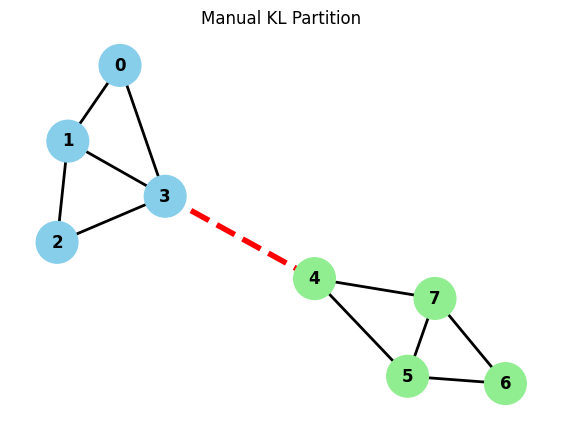

In [14]:
final_crossing_edges_kl = kl_crossing_edges(G, final_A_kl, final_B_kl)

node_colors = []

for node in G.nodes():
    if node in final_A_kl:
        node_colors.append("skyblue")
    else:
        node_colors.append("lightgreen")

cut_edge_set = {tuple(sorted(edge)) for edge in final_crossing_edges_kl}

normal_edges = []

for edge in G.edges():
    if tuple(sorted(edge)) not in cut_edge_set:
        normal_edges.append(edge)

plt.figure(figsize=(7, 5))

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=900)
nx.draw_networkx_edges(G, pos, edgelist=normal_edges, width=2)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=final_crossing_edges_kl,
    edge_color="red",
    width=4,
    style="dashed"
)

nx.draw_networkx_labels(G, pos, font_size=12, font_weight="bold")

plt.title("Manual KL Partition")
plt.axis("off")
plt.show()

## KL using NetworkX library

<div style="padding:12px 16px; background:#f8fafc; border:1px solid #dbe3ef; border-radius:10px;">
  <b>Purpose:</b> compare the manual KL result with NetworkX's built-in KL bisection function.
</div>

[Back to KL section](#kl) | [Back to top](#top)


### Optional Cell: KL using NetworkX library

This cell runs NetworkX's built-in Kernighan-Lin bisection function. It is included for comparison with the manual KL implementation.


In [15]:
partition_k= nx.algorithms.community.kernighan_lin_bisection(G)
print(partition_k)

({4, 5, 6, 7}, {0, 1, 2, 3})


### Optional Cell: Show NetworkX KL partitions

This cell prints the two partitions returned by the built-in NetworkX KL algorithm.


In [16]:
part1, part2 = partition_k

print("Partition 1:", sorted(part1))
print("Partition 2:", sorted(part2))

Partition 1: [4, 5, 6, 7]
Partition 2: [0, 1, 2, 3]


### Optional Cell: Crossing edges for NetworkX KL

This cell calculates and prints the crossing edges and cut size for the built-in KL result.


In [17]:
crossing_edges = []

for u, v in G.edges():
    if (u in part1 and v in part2) or (u in part2 and v in part1):
        crossing_edges.append((u, v))

print("Crossing edges:", crossing_edges)
print("Cut size:", len(crossing_edges))

Crossing edges: [(3, 4)]
Cut size: 1


### Optional Cell: Visualize NetworkX KL result

This cell draws the partition found by the built-in KL algorithm and highlights crossing edges in red.


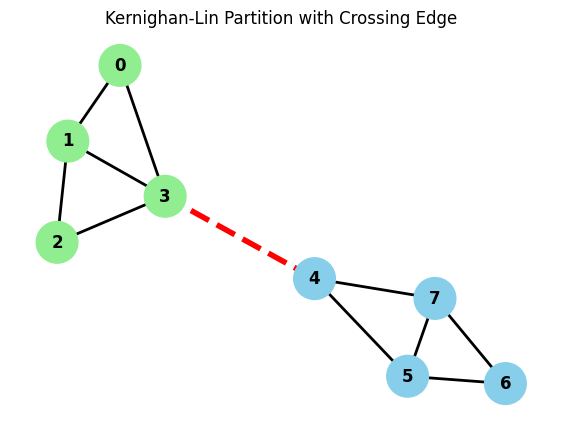

In [18]:
node_colors = []

for node in G.nodes():
    if node in part1:
        node_colors.append("skyblue")
    else:
        node_colors.append("lightgreen")

plt.figure(figsize=(7,5))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    node_size=900
)

normal_edges = []

for edge in G.edges():
    if edge not in crossing_edges and (edge[1], edge[0]) not in crossing_edges:
        normal_edges.append(edge)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=normal_edges,
    width=2
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=crossing_edges,
    edge_color="red",
    width=4,
    style="dashed"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=12,
    font_weight="bold"
)

plt.title("Kernighan-Lin Partition with Crossing Edge")
plt.axis("off")
plt.show()

<a id="fm"></a>

# 3. Fiduccia-Mattheyses (FM) Algorithm

<div style="padding:16px 20px; border-left:6px solid #16a34a; background:#f0fdf4; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#14532d;">Core idea</h3>
  <p style="margin:0; color:#334155;">FM improves a partition by moving one node at a time instead of swapping pairs.</p>
</div>

| Item | Description |
|---|---|
| Move type | Single-node move |
| Main measure | Gain = external edges minus internal edges |
| Balance rule | Keep the two partitions close in size |
| Expected result | Two natural communities separated by the bridge edge |

[Back to top](#top)


### FM Cell: Helper functions

This cell defines helper functions for the FM algorithm:

- `fm_crossing_edges`: finds crossing edges.
- `fm_cut_size`: counts crossing edges.
- `fm_gain_table`: creates the Node, Partition, Connections, External, Internal, Gain table.
- `fm_move_vertex`: moves one vertex from one partition to the other.


In [19]:
import pandas as pd

def fm_crossing_edges(G, A, B):
    crossing = []
    for u, v in G.edges():
        if (u in A and v in B) or (u in B and v in A):
            crossing.append((u, v))
    return crossing


def fm_cut_size(G, A, B):
    return len(fm_crossing_edges(G, A, B))


def fm_gain_table(G, A, B):
    rows = []

    for node in sorted(G.nodes()):
        connections = sorted(list(G.neighbors(node)))

        if node in A:
            partition = "A"
            same_partition = A
            other_partition = B
        else:
            partition = "B"
            same_partition = B
            other_partition = A

        external = 0
        internal = 0

        for neighbor in connections:
            if neighbor in same_partition:
                internal += 1
            elif neighbor in other_partition:
                external += 1

        gain = external - internal

        rows.append({
            "Node": node,
            "Partition": partition,
            "Connections": connections,
            "External": external,
            "Internal": internal,
            "Gain": gain
        })

    return pd.DataFrame(rows)


def fm_vertex_gain(G, node, A, B):
    gain_df = fm_gain_table(G, A, B)
    return int(gain_df[gain_df["Node"] == node]["Gain"].iloc[0])


def fm_move_vertex(node, A, B):
    A = set(A)
    B = set(B)

    if node in A:
        A.remove(node)
        B.add(node)
        direction = "A -> B"
    else:
        B.remove(node)
        A.add(node)
        direction = "B -> A"

    return A, B, direction

### FM Cell: Initial partition and gain table

This cell sets the same initial balanced partition used for KL and displays the initial FM gain table. In FM, a positive gain means moving that single node can reduce the cut.


In [20]:
A = {0, 1, 2, 4}
B = {3, 5, 6, 7}

print("Initial FM Partition")
print("A =", sorted(A))
print("B =", sorted(B))

print("\nInitial crossing edges:")
print(fm_crossing_edges(G, A, B))

print("\nInitial cut size:", fm_cut_size(G, A, B))

print("\nFM Initial Gain Table")
display(fm_gain_table(G, A, B))

Initial FM Partition
A = [0, 1, 2, 4]
B = [3, 5, 6, 7]

Initial crossing edges:
[(0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (4, 7)]

Initial cut size: 6

FM Initial Gain Table


,Node,Partition,Connections,External,Internal,Gain
0,0,A,"[1, 3]",1,1,0
1,1,A,"[0, 2, 3]",1,2,-1
2,2,A,"[1, 3]",1,1,0
3,3,B,"[0, 1, 2, 4]",4,0,4
4,4,A,"[3, 5, 7]",3,0,3
5,5,B,"[4, 6, 7]",1,2,-1
6,6,B,"[5, 7]",0,2,-2
7,7,B,"[4, 5, 6]",1,2,-1


### FM Cell: Manual FM function

This cell defines the manual FM algorithm. It selects the best unlocked vertex, moves it, locks it, tracks cumulative gain, and finally applies the best balanced set of moves.


In [21]:
def fm_manual_clean(G, A, B, balance_tolerance=2):
    A = set(A)
    B = set(B)

    print("=" * 60)
    print("MANUAL FIDUCCIA-MATTHEYSES ALGORITHM")
    print("=" * 60)

    print("Starting A:", sorted(A))
    print("Starting B:", sorted(B))
    print("Starting crossing edges:", fm_crossing_edges(G, A, B))
    print("Starting cut size:", fm_cut_size(G, A, B))

    A_work = set(A)
    B_work = set(B)
    locked = set()

    move_records = []
    partition_states = []
    cumulative_gain = 0

    for step in range(len(G.nodes())):
        best_node = None
        best_gain = None
        best_direction = None
        best_A = None
        best_B = None

        for node in sorted(G.nodes()):
            if node in locked:
                continue

            gain = fm_vertex_gain(G, node, A_work, B_work)
            temp_A, temp_B, direction = fm_move_vertex(node, A_work, B_work)

            if abs(len(temp_A) - len(temp_B)) > balance_tolerance:
                continue

            if best_gain is None or gain > best_gain:
                best_gain = gain
                best_node = node
                best_direction = direction
                best_A = temp_A
                best_B = temp_B

        if best_node is None:
            break

        A_work = best_A
        B_work = best_B
        locked.add(best_node)

        cumulative_gain += best_gain
        balanced = len(A_work) == len(B_work)

        move_records.append({
            "Step": step + 1,
            "Moved Node": best_node,
            "Direction": best_direction,
            "Gain": best_gain,
            "Cumulative Gain": cumulative_gain,
            "Cut After Move": fm_cut_size(G, A_work, B_work),
            "Balanced": balanced
        })

        partition_states.append((set(A_work), set(B_work)))

    move_df = pd.DataFrame(move_records)

    print("\nFM Move Table")
    display(move_df)

    best_index = None
    best_cumulative_gain = 0

    for i, record in enumerate(move_records):
        if record["Balanced"] and record["Cumulative Gain"] > best_cumulative_gain:
            best_cumulative_gain = record["Cumulative Gain"]
            best_index = i

    if best_index is None:
        print("\nNo positive balanced improvement found.")
        return A, B

    final_A, final_B = partition_states[best_index]

    print("\nBest balanced cumulative gain:", best_cumulative_gain)
    print("Apply first", best_index + 1, "move(s).")

    print("\nApplied moves:")
    for record in move_records[:best_index + 1]:
        print(
            f"Move node {record['Moved Node']} "
            f"({record['Direction']}), gain = {record['Gain']}"
        )

    print("\nFinal FM Partition")
    print("A =", sorted(final_A))
    print("B =", sorted(final_B))
    print("Final crossing edges:", fm_crossing_edges(G, final_A, final_B))
    print("Final cut size:", fm_cut_size(G, final_A, final_B))

    return final_A, final_B

### FM Cell: Run manual FM

This cell runs the manual FM algorithm. The expected useful moves are: move node 3 from B to A, then move node 4 from A to B.


In [22]:
A = {0, 1, 2, 4}
B = {3, 5, 6, 7}

final_A_fm, final_B_fm = fm_manual_clean(G, A, B)

MANUAL FIDUCCIA-MATTHEYSES ALGORITHM
Starting A: [0, 1, 2, 4]
Starting B: [3, 5, 6, 7]
Starting crossing edges: [(0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (4, 7)]
Starting cut size: 6

FM Move Table


,Step,Moved Node,Direction,Gain,Cumulative Gain,Cut After Move,Balanced
0,1,3,B -> A,4,4,2,False
1,2,4,A -> B,1,5,1,True
2,3,0,A -> B,-2,3,3,False
3,4,6,B -> A,-2,1,5,True
4,5,1,A -> B,-1,0,6,False
5,6,5,B -> A,-1,-1,7,True
6,7,7,B -> A,1,0,6,False
7,8,2,A -> B,0,0,6,True



Best balanced cumulative gain: 5
Apply first 2 move(s).

Applied moves:
Move node 3 (B -> A), gain = 4
Move node 4 (A -> B), gain = 1

Final FM Partition
A = [0, 1, 2, 3]
B = [4, 5, 6, 7]
Final crossing edges: [(3, 4)]
Final cut size: 1


### FM Cell: Final gain table and crossing edge

This cell displays the final FM gain table and prints the final crossing edge and cut size.


In [23]:
print("Final FM Gain Table")
display(fm_gain_table(G, final_A_fm, final_B_fm))

print("Final FM crossing edges:", fm_crossing_edges(G, final_A_fm, final_B_fm))
print("Final FM cut size:", fm_cut_size(G, final_A_fm, final_B_fm))

Final FM Gain Table


,Node,Partition,Connections,External,Internal,Gain
0,0,A,"[1, 3]",0,2,-2
1,1,A,"[0, 2, 3]",0,3,-3
2,2,A,"[1, 3]",0,2,-2
3,3,A,"[0, 1, 2, 4]",1,3,-2
4,4,B,"[3, 5, 7]",1,2,-1
5,5,B,"[4, 6, 7]",0,3,-3
6,6,B,"[5, 7]",0,2,-2
7,7,B,"[4, 5, 6]",0,3,-3


Final FM crossing edges: [(3, 4)]
Final FM cut size: 1


### FM Cell: Draw final FM partition

This cell draws the final FM partition. The red dashed edge is the crossing edge between the two final communities.


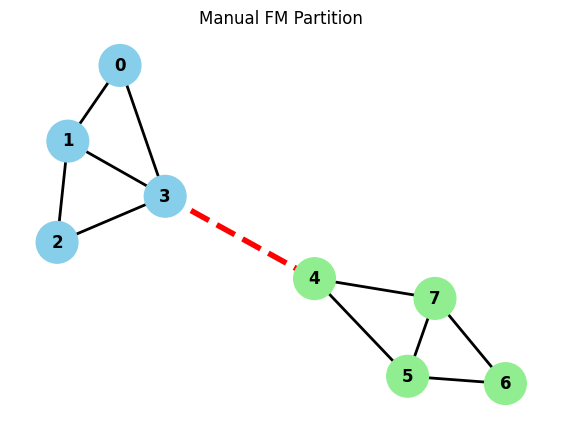

In [24]:
final_crossing_edges_fm = fm_crossing_edges(G, final_A_fm, final_B_fm)

node_colors = []

for node in G.nodes():
    if node in final_A_fm:
        node_colors.append("skyblue")
    else:
        node_colors.append("lightgreen")

cut_edge_set = {tuple(sorted(edge)) for edge in final_crossing_edges_fm}

normal_edges = []

for edge in G.edges():
    if tuple(sorted(edge)) not in cut_edge_set:
        normal_edges.append(edge)

plt.figure(figsize=(7, 5))

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=900)
nx.draw_networkx_edges(G, pos, edgelist=normal_edges, width=2)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=final_crossing_edges_fm,
    edge_color="red",
    width=4,
    style="dashed"
)

nx.draw_networkx_labels(G, pos, font_size=12, font_weight="bold")

plt.title("Manual FM Partition")
plt.axis("off")
plt.show()

<a id="metis"></a>

# 4. Multilevel Graph Partitioning / METIS

<div style="padding:16px 20px; border-left:6px solid #7c3aed; background:#f5f3ff; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#4c1d95;">Core idea</h3>
  <p style="margin:0; color:#334155;">Shrink the graph, partition the smaller graph, then expand back while refining the result.</p>
</div>

| Item | Description |
|---|---|
| Dedicated library | `pymetis` |
| Partition count | `nparts = 2` |
| Output | Membership list, readable partitions, crossing edges, and visual result |
| Note | NetworkX does not directly provide METIS/multilevel partitioning |

[Back to top](#top)


### METIS Cell: Install dependency

This cell installs `pymetis` if it is not already installed. Run it only when your environment does not have `pymetis` available.


In [25]:
! pip install pymetis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.9/275.9 kB 6.1 MB/s eta 0:00:00


### METIS Cell: Run 2-way multilevel partitioning

This cell runs METIS with `nparts = 2`, which is the natural choice for this graph. It converts graph nodes into index-based adjacency lists required by PyMetis.


In [29]:
import pymetis

# Use sorted nodes to keep node order correct
nodes = sorted(G.nodes())

# Create mapping: node -> index
node_to_index = {node: i for i, node in enumerate(nodes)}

# Create adjacency list using index values
adjacency = []

for node in nodes:
    neighbors = []
    for neighbor in G.neighbors(node):
        neighbors.append(node_to_index[neighbor])
    adjacency.append(neighbors)

# Number of partitions
nparts = 2

# Run METIS partitioning
cuts, membership = pymetis.part_graph(nparts, adjacency=adjacency)

print("METIS membership:")
print(membership)

print("Number of cuts:", cuts)

METIS membership:
array('q', [0, 0, 0, 0, 1, 1, 1, 1])
Number of cuts: 1


### METIS Cell: Convert membership to readable partitions

PyMetis returns a membership list. This cell converts that list into readable partition groups.


In [30]:
# Convert membership result into partition groups

partitions = {}

for node, part in zip(nodes, membership):
    if part not in partitions:
        partitions[part] = []
    partitions[part].append(node)

print("METIS Partitions:")

for part, node_list in partitions.items():
    print(f"Partition {part}:", sorted(node_list))

METIS Partitions:
Partition 0: [0, 1, 2, 3]
Partition 1: [4, 5, 6, 7]


### METIS Cell: Crossing edges and cut size

This cell finds edges whose endpoints belong to different METIS partitions. These are the crossing edges.


In [31]:
# Create dictionary: node -> partition
node_partition = {}

for node, part in zip(nodes, membership):
    node_partition[node] = part

# Find crossing edges
metis_crossing_edges = []

for u, v in G.edges():
    if node_partition[u] != node_partition[v]:
        metis_crossing_edges.append((u, v))

print("METIS crossing edges:")
print(metis_crossing_edges)

print("METIS cut size:", len(metis_crossing_edges))

METIS crossing edges:
[(3, 4)]
METIS cut size: 1


### METIS Cell: Draw METIS result

This cell visualizes the 2-way METIS partition and highlights crossing edges in red.


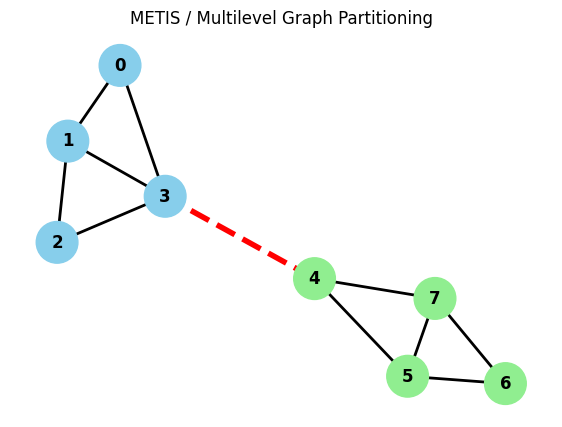

In [32]:
# Draw METIS partition result

colors = ["skyblue", "lightgreen", "orange", "violet", "pink"]

node_colors = []

for node in G.nodes():
    part = node_partition[node]
    node_colors.append(colors[part])

cut_edge_set = {tuple(sorted(edge)) for edge in metis_crossing_edges}

normal_edges = []

for edge in G.edges():
    if tuple(sorted(edge)) not in cut_edge_set:
        normal_edges.append(edge)

plt.figure(figsize=(7, 5))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    node_size=900
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=normal_edges,
    width=2
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=metis_crossing_edges,
    edge_color="red",
    width=4,
    style="dashed"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=12,
    font_weight="bold"
)

plt.title("METIS / Multilevel Graph Partitioning")
plt.axis("off")
plt.show()

<a id="spectral"></a>

# 5. Spectral Graph Partitioning

<div style="padding:16px 20px; border-left:6px solid #0891b2; background:#ecfeff; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#164e63;">Core idea</h3>
  <p style="margin:0; color:#334155;">Convert the graph into matrices and use the Fiedler vector to split nodes into two groups.</p>
</div>

| Step | Meaning |
|---|---|
| Build `A` | Adjacency matrix |
| Build `D` | Degree matrix |
| Compute `L = D - A` | Graph Laplacian |
| Use second-smallest eigenvector | Fiedler vector |
| Split by sign | Positive vs negative values become partitions |

[Back to top](#top)


### Spectral Cell: Build matrices \(A\), \(D\), and \(L\)

This cell creates the adjacency matrix, degree matrix, and graph Laplacian. Spectral partitioning is based on the Laplacian matrix \(L = D - A\).


In [33]:
import numpy as np
import pandas as pd

# Adjacency matrix
A_matrix = nx.to_numpy_array(G, nodelist=sorted(G.nodes()))

# Degree matrix
degrees = np.sum(A_matrix, axis=1)
D_matrix = np.diag(degrees)

# Laplacian matrix
L_matrix = D_matrix - A_matrix

print("Adjacency Matrix A:")
display(pd.DataFrame(A_matrix.astype(int), index=sorted(G.nodes()), columns=sorted(G.nodes())))

print("Degree Matrix D:")
display(pd.DataFrame(D_matrix.astype(int), index=sorted(G.nodes()), columns=sorted(G.nodes())))

print("Laplacian Matrix L = D - A:")
display(pd.DataFrame(L_matrix.astype(int), index=sorted(G.nodes()), columns=sorted(G.nodes())))

Adjacency Matrix A:


,0,1,2,3,4,5,6,7
0,0,1,0,1,0,0,0,0
1,1,0,1,1,0,0,0,0
2,0,1,0,1,0,0,0,0
3,1,1,1,0,1,0,0,0
4,0,0,0,1,0,1,0,1
5,0,0,0,0,1,0,1,1
6,0,0,0,0,0,1,0,1
7,0,0,0,0,1,1,1,0


Degree Matrix D:


,0,1,2,3,4,5,6,7
0,2,0,0,0,0,0,0,0
1,0,3,0,0,0,0,0,0
2,0,0,2,0,0,0,0,0
3,0,0,0,4,0,0,0,0
4,0,0,0,0,3,0,0,0
5,0,0,0,0,0,3,0,0
6,0,0,0,0,0,0,2,0
7,0,0,0,0,0,0,0,3


Laplacian Matrix L = D - A:


,0,1,2,3,4,5,6,7
0,2,-1,0,-1,0,0,0,0
1,-1,3,-1,-1,0,0,0,0
2,0,-1,2,-1,0,0,0,0
3,-1,-1,-1,4,-1,0,0,0
4,0,0,0,-1,3,-1,0,-1
5,0,0,0,0,-1,3,-1,-1
6,0,0,0,0,0,-1,2,-1
7,0,0,0,0,-1,-1,-1,3


### Spectral Cell: Eigenvalues and eigenvectors

This cell calculates the eigenvalues and eigenvectors of the Laplacian matrix. The second-smallest eigenvector is used for partitioning.


In [34]:
eigvals, eigvecs = np.linalg.eigh(L_matrix)

print("Eigenvalues:")
display(pd.DataFrame({
    "Index": list(range(len(eigvals))),
    "Eigenvalue": eigvals
}))

Eigenvalues:


,Index,Eigenvalue
0,0,-4.194641e-16
1,1,3.186694e-01
2,2,2.000000e+00
3,3,2.357926e+00
4,4,4.000000e+00
5,5,4.000000e+00
6,6,4.000000e+00
7,7,5.323404e+00


### Spectral Cell: Fiedler vector

This cell extracts the Fiedler vector and displays its value for each node. Nodes with similar signs usually belong to the same partition.


In [35]:
# Fiedler vector = eigenvector corresponding to the second smallest eigenvalue
fiedler_vector = eigvecs[:, 1]

fiedler_df = pd.DataFrame({
    "Node": sorted(G.nodes()),
    "Fiedler Value": fiedler_vector
})

print("Fiedler Vector Table:")
display(fiedler_df)

Fiedler Vector Table:


,Node,Fiedler Value
0,0,-0.374738
1,1,-0.374738
2,2,-0.374738
3,3,-0.255320
4,4,0.184295
5,5,0.374738
6,6,0.445763
7,7,0.374738


### Spectral Cell: Create partition from Fiedler signs

This cell separates nodes based on whether their Fiedler vector value is positive or negative.


In [36]:
partition_positive = set()
partition_negative = set()

for node, value in zip(sorted(G.nodes()), fiedler_vector):
    if value >= 0:
        partition_positive.add(node)
    else:
        partition_negative.add(node)

print("Spectral Partition:")
print("Partition 1:", sorted(partition_positive))
print("Partition 2:", sorted(partition_negative))

Spectral Partition:
Partition 1: [4, 5, 6, 7]
Partition 2: [0, 1, 2, 3]


### Spectral Cell: Crossing edges and cut size

This cell calculates the crossing edges between the two spectral partitions.


In [37]:
spectral_crossing_edges = []

for u, v in G.edges():
    if (u in partition_positive and v in partition_negative) or (u in partition_negative and v in partition_positive):
        spectral_crossing_edges.append((u, v))

print("Spectral crossing edges:", spectral_crossing_edges)
print("Spectral cut size:", len(spectral_crossing_edges))

Spectral crossing edges: [(3, 4)]
Spectral cut size: 1


### Spectral Cell: Draw spectral partition

This cell visualizes the spectral partition and highlights the crossing edge in red.


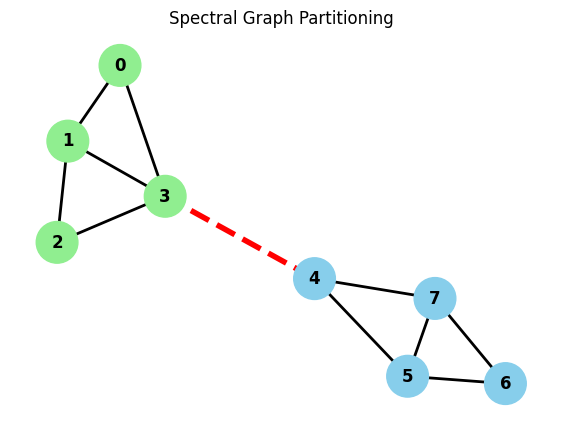

In [38]:
node_colors = []

for node in G.nodes():
    if node in partition_positive:
        node_colors.append("skyblue")
    else:
        node_colors.append("lightgreen")

cut_edge_set = {tuple(sorted(edge)) for edge in spectral_crossing_edges}

normal_edges = []

for edge in G.edges():
    if tuple(sorted(edge)) not in cut_edge_set:
        normal_edges.append(edge)

plt.figure(figsize=(7, 5))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    node_size=900
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=normal_edges,
    width=2
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=spectral_crossing_edges,
    edge_color="red",
    width=4,
    style="dashed"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=12,
    font_weight="bold"
)

plt.title("Spectral Graph Partitioning")
plt.axis("off")
plt.show()

<a id="mcl-library"></a>

# 6. Markov Clustering (MCL) Using Library

<div style="padding:16px 20px; border-left:6px solid #f59e0b; background:#fffbeb; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#78350f;">Core idea</h3>
  <p style="margin:0; color:#334155;">Use random-walk flow to find dense groups. Strong within-community flow remains, while weak between-community flow fades.</p>
</div>

| Item | Description |
|---|---|
| Dedicated library | `markov_clustering` |
| Input | Adjacency matrix from the graph |
| Output | Cluster tuples converted into readable groups |
| Note | NetworkX does not include MCL directly |

[Back to top](#top)


### MCL Library Cell: Install dependency

This cell installs the `markov_clustering` package if it is missing. Run it only when needed.


In [39]:
! pip install markov_clustering

### MCL Library Cell: Basic MCL run

This cell runs Markov Clustering using the external library and prints the cluster tuples directly.


In [44]:
import markov_clustering as mc
matrix=nx.to_numpy_array(G)
result=mc.run_mcl(matrix)
clusters=mc.get_clusters(result)
print(clusters)

[(0, 1, 2, 3), (4, 5, 6, 7)]


### MCL Library Cell: Clean MCL run

This cell runs MCL again with a clearer structure: convert graph to matrix, run MCL, extract clusters, and print the result.


In [45]:
import markov_clustering as mc
import numpy as np
import pandas as pd

# Convert graph to adjacency matrix
matrix = nx.to_numpy_array(G, nodelist=sorted(G.nodes()))

# Run Markov Clustering
result = mc.run_mcl(matrix)

# Get clusters
clusters = mc.get_clusters(result)

print("MCL Clusters:")
print(clusters)

MCL Clusters:
[(0, 1, 2, 3), (4, 5, 6, 7)]


### MCL Library Cell: Display clusters clearly

This cell prints each MCL cluster on a separate line, making the result easier to read.


In [46]:
print("Markov Clustering Result")

for i, cluster in enumerate(clusters, start=1):
    print(f"Cluster {i}:", list(cluster))

Markov Clustering Result
Cluster 1: [0, 1, 2, 3]
Cluster 2: [4, 5, 6, 7]


<a id="manual-mcl"></a>

# 7. Manual Markov Clustering Without Library

<div style="padding:16px 20px; border-left:6px solid #ea580c; background:#fff7ed; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#7c2d12;">Core idea</h3>
  <p style="margin:0; color:#334155;">Implement the main MCL operations manually: self-loops, normalization, expansion, inflation, pruning, and cluster extraction.</p>
</div>

| Manual MCL operation | What it does |
|---|---|
| Add self-loops | Allows a random walk to stay at the same node |
| Normalize rows | Turns adjacency values into probabilities |
| Expansion | Simulates longer random walks |
| Inflation | Strengthens high-probability paths and weakens low-probability paths |
| Pruning | Removes very small transition probabilities |
| Connected components | Extracts final clusters from the converged matrix |

[Back to top](#top)


### Manual MCL Cell: Helper functions

This cell defines the core manual MCL operations:

- row normalization
- adding self-loops
- expansion
- inflation
- pruning small probabilities


In [47]:
import numpy as np
import pandas as pd

def normalize_rows(M):
    """
    Convert each row into probability values.
    Each row sum becomes 1.
    """
    row_sums = M.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    return M / row_sums


def add_self_loops_matrix(G, nodes):
    """
    Create adjacency matrix and add self-loops.
    Self-loop means each node can stay at itself.
    """
    A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)
    np.fill_diagonal(A, 1.0)
    return A


def expand(M, power=2):
    """
    Expansion step:
    M^2 means random walk of length 2.
    """
    result = M.copy()
    for _ in range(power - 1):
        result = result @ M
    return result


def inflate(M, r=2):
    """
    Inflation step:
    Raise each value to power r, then normalize rows.
    Higher probabilities become stronger.
    Lower probabilities become weaker.
    """
    M_power = np.power(M, r)
    return normalize_rows(M_power)


def prune(M, threshold=0.0001):
    """
    Remove very small probabilities.
    This makes weak connections disappear.
    """
    M_pruned = M.copy()
    M_pruned[M_pruned < threshold] = 0
    return normalize_rows(M_pruned)

### Manual MCL Cell: Initial transition matrix

This cell creates the transition matrix. Each row represents a node, and each value represents the probability of moving to another node in one random-walk step.


In [48]:
nodes = sorted(G.nodes())

# Step 1: adjacency matrix with self-loops
A_matrix = add_self_loops_matrix(G, nodes)

# Step 2: transition matrix
M = normalize_rows(A_matrix)

print("Initial Transition Matrix Created")
print("Rows represent source nodes, columns represent destination nodes.")

M_initial_df = pd.DataFrame(M, index=nodes, columns=nodes)
display(M_initial_df.round(3))

Initial Transition Matrix Created
Rows represent source nodes, columns represent destination nodes.


,0,1,2,3,4,5,6,7
0,0.333,0.333,0.000,0.333,0.00,0.000,0.000,0.000
1,0.250,0.250,0.250,0.250,0.00,0.000,0.000,0.000
2,0.000,0.333,0.333,0.333,0.00,0.000,0.000,0.000
3,0.200,0.200,0.200,0.200,0.20,0.000,0.000,0.000
4,0.000,0.000,0.000,0.250,0.25,0.250,0.000,0.250
5,0.000,0.000,0.000,0.000,0.25,0.250,0.250,0.250
6,0.000,0.000,0.000,0.000,0.00,0.333,0.333,0.333
7,0.000,0.000,0.000,0.000,0.25,0.250,0.250,0.250


### Manual MCL Cell: Manual MCL function

This cell defines the full manual MCL loop: expansion, inflation, pruning, and convergence checking.


In [49]:
def manual_mcl(G, expansion_power=2, inflation_r=2, max_iter=50, threshold=0.0001, convergence_tol=0.000001):
    nodes = sorted(G.nodes())

    # Create initial transition matrix
    A_matrix = add_self_loops_matrix(G, nodes)
    M = normalize_rows(A_matrix)

    records = []

    for iteration in range(1, max_iter + 1):
        previous_M = M.copy()

        # Expansion
        M = expand(M, power=expansion_power)

        # Inflation
        M = inflate(M, r=inflation_r)

        # Pruning
        M = prune(M, threshold=threshold)

        # Check convergence
        difference = np.linalg.norm(M - previous_M)

        records.append({
            "Iteration": iteration,
            "Difference": difference
        })

        if difference < convergence_tol:
            break

    iteration_df = pd.DataFrame(records)

    return M, iteration_df, nodes

### Manual MCL Cell: Run manual MCL

This cell runs the manual MCL algorithm and displays the iteration differences and final matrix.


In [53]:
mcl_result_matrix, mcl_iteration_df, nodes = manual_mcl(
    G,
    expansion_power=2,
    inflation_r=2,
    max_iter=50,
    threshold=0.0001,
    convergence_tol=0.000001
)

print("MCL Iteration Table")
display(mcl_iteration_df)

print("Final MCL Matrix")
mcl_result_df = pd.DataFrame(mcl_result_matrix, index=nodes, columns=nodes)
display(mcl_result_df.round(3))

MCL Iteration Table


,Iteration,Difference
0,1,0.498768
1,2,0.453546
2,3,0.515805
3,4,0.463896
4,5,0.417740
5,6,0.184326
6,7,0.016409
7,8,0.000000


Final MCL Matrix


,0,1,2,3,4,5,6,7
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.5
5,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.5
6,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.5
7,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.5


### Manual MCL Cell: Extract clusters

This cell converts the final MCL matrix into clusters by connecting nodes that still have strong transition probability.


In [54]:
def extract_mcl_clusters(M, nodes, threshold=0.001):
    """
    Build a graph from the final MCL matrix.
    If two nodes still have strong transition probability,
    they are treated as belonging to the same cluster.
    """
    H = nx.Graph()
    H.add_nodes_from(nodes)

    for i, u in enumerate(nodes):
        for j, v in enumerate(nodes):
            if i != j:
                if M[i, j] > threshold or M[j, i] > threshold:
                    H.add_edge(u, v)

    clusters = [sorted(list(component)) for component in nx.connected_components(H)]
    clusters = sorted(clusters, key=lambda x: x[0])

    return clusters


mcl_clusters = extract_mcl_clusters(mcl_result_matrix, nodes)

print("Manual MCL Clusters:")
for i, cluster in enumerate(mcl_clusters, start=1):
    print(f"Cluster {i}:", cluster)

Manual MCL Clusters:
Cluster 1: [0, 1, 2, 3]
Cluster 2: [4, 5, 6, 7]


### Manual MCL Cell: Crossing edges and cut size

This cell calculates the crossing edges between the manually extracted MCL clusters.


In [55]:
cluster_1 = set(mcl_clusters[0])
cluster_2 = set(mcl_clusters[1])

mcl_crossing_edges = []

for u, v in G.edges():
    if (u in cluster_1 and v in cluster_2) or (u in cluster_2 and v in cluster_1):
        mcl_crossing_edges.append((u, v))

print("Partition 1:", sorted(cluster_1))
print("Partition 2:", sorted(cluster_2))
print("MCL crossing edges:", mcl_crossing_edges)
print("MCL cut size:", len(mcl_crossing_edges))

Partition 1: [0, 1, 2, 3]
Partition 2: [4, 5, 6, 7]
MCL crossing edges: [(3, 4)]
MCL cut size: 1


### Manual MCL Cell: Draw manual MCL result

This cell visualizes the manual MCL clustering result and highlights the crossing edge in red.


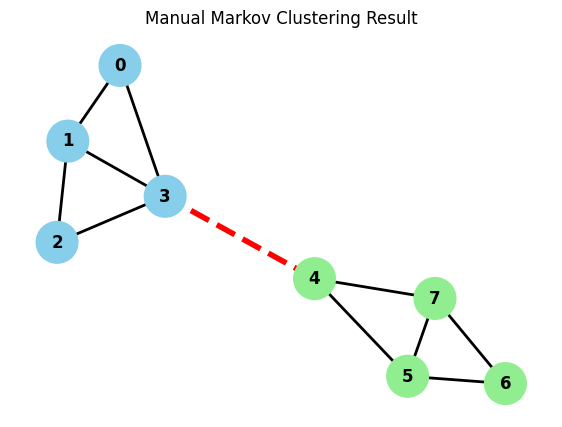

In [52]:
node_colors = []

for node in G.nodes():
    if node in cluster_1:
        node_colors.append("skyblue")
    else:
        node_colors.append("lightgreen")

cut_edge_set = {tuple(sorted(edge)) for edge in mcl_crossing_edges}

normal_edges = []

for edge in G.edges():
    if tuple(sorted(edge)) not in cut_edge_set:
        normal_edges.append(edge)

plt.figure(figsize=(7, 5))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    node_size=900
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=normal_edges,
    width=2
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=mcl_crossing_edges,
    edge_color="red",
    width=4,
    style="dashed"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=12,
    font_weight="bold"
)

plt.title("Manual Markov Clustering Result")
plt.axis("off")
plt.show()